# Retail Sales Analysis with Python
## A beginner project: from raw records to business findings

**Source:** Fictional practice data generated for this project; no real company or customer data. **Period:** January 2024–December 2025. **Currency:** Indian rupees (₹).

**Main question:** What drives completed sales, and how do sales differ across products, categories, regions and months?

**How to use:** Keep this notebook and `retail_sales_practice.csv` in the same folder. In Jupyter, choose Run All. In Google Colab, open the notebook and upload the CSV using the Files panel before running. Dependencies: pandas and matplotlib. All outputs below have already been calculated.

Each row is one product line within an order. An order may have multiple rows and mixed line statuses. Completed sales exclude returned and cancelled lines. Our average order value is the completed value per order with at least one completed line; it is not the original checkout basket value.

### Data dictionary
| Column | Meaning |
|---|---|
| order_id | Order reference; repeated across products in a basket |
| order_date | Order date in YYYY-MM-DD format |
| product | Product name |
| category | Product category |
| quantity | Units on the product line, positive for every status |
| unit_price | Price per unit in INR |
| region | North, South, East or West; may be missing |
| payment_method | UPI, Card or Cash; may be missing |
| status | Completed, Returned or Cancelled for this product line |


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('retail_sales_practice.csv')
print('Rows and columns:', df.shape)
print(df.head().to_string(index=False))

Rows and columns: (3231, 9)
order_id order_date        product    category  quantity  unit_price region payment_method    status
ORD00015 2024-01-02   Water Bottle      Sports         4         499   West           Card Completed
ORD00015 2024-01-02 Desk Organiser  Stationery         4         299   West           Card Completed
ORD00015 2024-01-02     Headphones Electronics         3        2499   West           Card Completed
ORD00028 2024-01-02         Hoodie    Clothing         4        1499   West            UPI Completed
ORD00040 2024-01-02    Storage Box        Home         3         449   West            UPI Completed


## Q1. Are there missing values or duplicate records?
`isna()` checks for empty cells. `duplicated()` identifies extra copies of entire rows, keeping the first occurrence unflagged. Repeated order IDs are valid and must not be removed on their own.

In [2]:
print('Missing values by column:')
print(df.isna().sum())
print('\nExact duplicate rows:', df.duplicated().sum())
print('\nOriginal column types:')
print(df.dtypes)

Missing values by column:
order_id           0
order_date         0
product            0
category           0
quantity           0
unit_price         0
region            29
payment_method    21
status             0
dtype: int64

Exact duplicate rows: 20

Original column types:
order_id          object
order_date        object
product           object
category          object
quantity           int64
unit_price         int64
region            object
payment_method    object
status            object
dtype: object


### Cleaning decisions
1. Keep the raw `df` and work on a copy.
2. Remove exact duplicate rows.
3. Strip surrounding spaces from categories.
4. Label missing region and payment method as `Unknown`. This preserves sales records without guessing the missing values.
5. Convert dates, using the known format. An invalid date raises an error rather than silently disappearing.
6. Preserve all statuses in `retail_clean`; use only completed lines for sales analysis.

For this synthetic file, exact repeated rows are deliberate duplicate errors. Real transaction systems should ideally provide a unique line ID before deduplication.

In [3]:
retail_clean = df.copy().drop_duplicates()
retail_clean['category'] = retail_clean['category'].str.strip()
retail_clean['region'] = retail_clean['region'].fillna('Unknown')
retail_clean['payment_method'] = retail_clean['payment_method'].fillna('Unknown')
retail_clean['order_date'] = pd.to_datetime(retail_clean['order_date'], format='%Y-%m-%d')

print('Rows after cleaning:', len(retail_clean))
print('Remaining duplicates:', retail_clean.duplicated().sum())
print('Remaining missing cells:', retail_clean.isna().sum().sum())
print('\nProduct lines by status:')
print(retail_clean['status'].value_counts())

Rows after cleaning: 3211
Remaining duplicates: 0
Remaining missing cells: 0

Product lines by status:
status
Completed    2889
Returned      199
Cancelled     123
Name: count, dtype: int64


## Q2. What is the sales value of each row?
Multiply units by price: 3 items at ₹499 each have a line value of ₹1,497. The calculation applies to every line; only completed lines contribute to our sales totals.

In [4]:
retail_clean['sales_value'] = retail_clean['quantity'] * retail_clean['unit_price']
completed_sales = retail_clean[retail_clean['status'] == 'Completed'].copy()
print(completed_sales[['order_id', 'product', 'quantity', 'unit_price', 'sales_value']].head().to_string(index=False))

order_id        product  quantity  unit_price  sales_value
ORD00015   Water Bottle         4         499         1996
ORD00015 Desk Organiser         4         299         1196
ORD00015     Headphones         3        2499         7497
ORD00028         Hoodie         4        1499         5996
ORD00040    Storage Box         3         449         1347


## Q3. What is the total completed sales value?
`sum()` adds the values of all completed product lines.

In [5]:
total_sales = completed_sales['sales_value'].sum()
print(f'Total completed sales: ₹{total_sales:,.2f}')

Total completed sales: ₹6,188,688.00


## Q4. How many unique orders were placed?
Count order IDs, not products or rows. Report both all orders and the subset with completed purchases.

In [6]:
all_orders = retail_clean['order_id'].nunique()
completed_orders = completed_sales['order_id'].nunique()
print('All unique orders:', all_orders)
print('Orders with at least one completed line:', completed_orders)

All unique orders: 1570
Orders with at least one completed line: 1521


## Q5. Which five products generated the most sales?
Group rows by product, add their sales values, then rank largest first.

product
Headphones           1014594
Bluetooth Speaker     811594
Jeans                 680022
Keyboard              522198
Hoodie                481179
Name: sales_value, dtype: int64


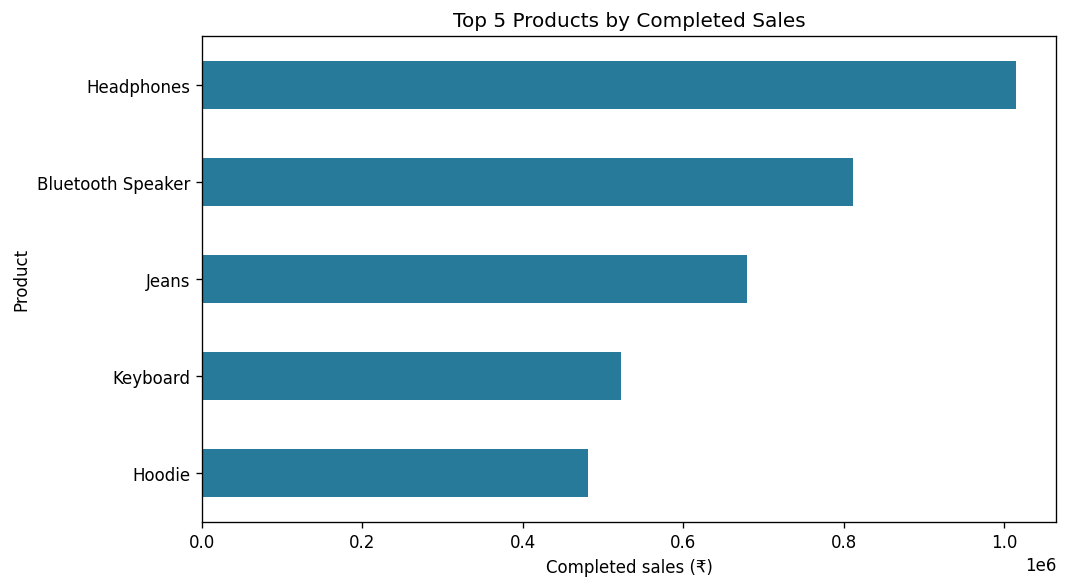

In [7]:
product_sales = completed_sales.groupby('product')['sales_value'].sum().sort_values(ascending=False)
top_products = product_sales.head(5)
print(top_products)
top_products.sort_values().plot(kind='barh', color='#287a9b', figsize=(9, 5))
plt.title('Top 5 Products by Completed Sales')
plt.xlabel('Completed sales (₹)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

**Finding:** Headphones leads with ₹1,014,594, representing 16.4% of completed sales. This ranks sales value, not unit volume or profit.

## Q6. Which categories sold the most units?
Use `quantity` to count units sold, rather than the number of transaction rows.

category
Electronics    1611
Home           1457
Stationery     1422
Sports         1412
Clothing       1410
Name: quantity, dtype: int64


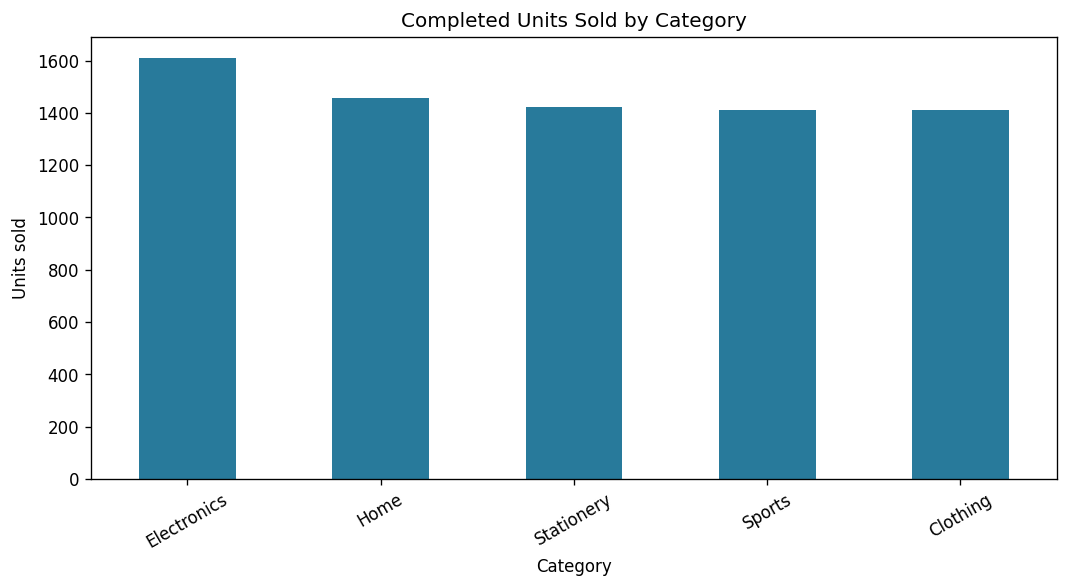

In [8]:
category_units = completed_sales.groupby('category')['quantity'].sum().sort_values(ascending=False)
print(category_units)
category_units.plot(kind='bar', color='#287a9b', figsize=(9, 5))
plt.title('Completed Units Sold by Category')
plt.xlabel('Category')
plt.ylabel('Units sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Finding:** Electronics sold the most units (1,611). A unit-volume leader need not be the sales-value leader because products have different prices.

## Q7. Which region generated the most sales?
Keep Unknown in the reconciliation, then exclude it from the ranking of named regions. Unknown sales remain in the overall total.

Sales including unknown region:
region
East       1033510
North       904005
South      2073090
Unknown      58770
West       2119313
Name: sales_value, dtype: int64

Leading known region:
region
West    2119313
Name: sales_value, dtype: int64


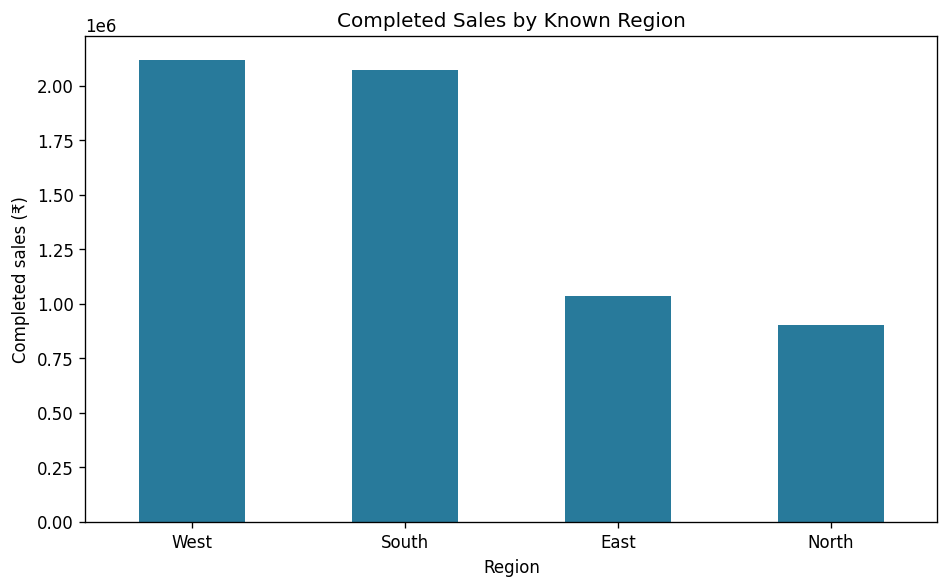

In [9]:
all_region_sales = completed_sales.groupby('region')['sales_value'].sum()
region_sales = all_region_sales.drop('Unknown', errors='ignore').sort_values(ascending=False)
print('Sales including unknown region:')
print(all_region_sales)
print('\nLeading known region:')
print(region_sales.head(1))
region_sales.plot(kind='bar', color='#287a9b', figsize=(8, 5))
plt.title('Completed Sales by Known Region')
plt.xlabel('Region')
plt.ylabel('Completed sales (₹)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Finding:** West leads known regions with ₹2,119,313. Another ₹58,770 (0.9% of total sales) has no known region and is excluded from this chart.

## Q8. How did sales change month by month?
`.dt.to_period('M')` combines year and month, so January 2024 and January 2025 stay separate. Sort by date for the line chart; do not sort by sales value.

order_date
2024-01    189210
2024-02    151487
2024-03    236038
2024-04    208648
2024-05    200252
2024-06    173937
2024-07    224501
2024-08    192367
2024-09    231990
2024-10    335464
2024-11    338058
2024-12    295451
2025-01    271869
2025-02    285639
2025-03    268608
2025-04    271526
2025-05    237516
2025-06    322150
2025-07    222214
2025-08    290568
2025-09    232921
2025-10    306603
2025-11    356351
2025-12    345320
Freq: M, Name: sales_value, dtype: int64

Annual completed sales:
order_date
2024    2777403
2025    3411285
Name: sales_value, dtype: int64
2025 change versus 2024: 22.82%


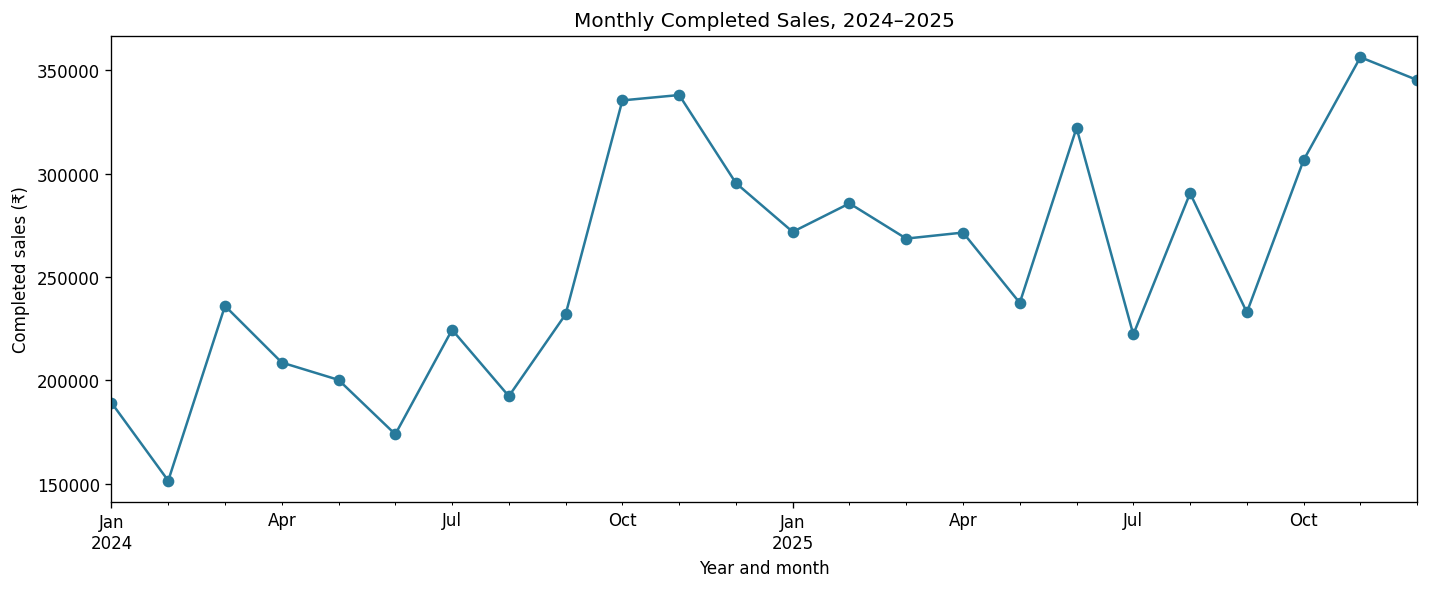

In [10]:
monthly_sales = completed_sales.groupby(
    completed_sales['order_date'].dt.to_period('M')
)['sales_value'].sum().sort_index()
print(monthly_sales)
monthly_sales.plot(kind='line', marker='o', color='#287a9b', figsize=(12, 5))
plt.title('Monthly Completed Sales, 2024–2025')
plt.xlabel('Year and month')
plt.ylabel('Completed sales (₹)')
plt.tight_layout()
plt.show()

annual_sales = completed_sales.groupby(completed_sales['order_date'].dt.year)['sales_value'].sum()
growth = (annual_sales.loc[2025] / annual_sales.loc[2024] - 1) * 100
print('\nAnnual completed sales:')
print(annual_sales)
print(f'2025 change versus 2024: {growth:.2f}%')

**Finding:** Monthly sales peaked in 2025-11 at ₹356,351, and were lowest in 2024-02 at ₹151,487. Annual sales changed by 22.82% in 2025. This synthetic pattern does not establish causes such as promotions, demand shifts or marketing effectiveness.

## Q9. What was the average order value?
Total completed sales ÷ unique orders with at least one completed line. Taking the mean of individual rows would calculate average line value, not average order value.

In [11]:
average_order_value = total_sales / completed_orders
print(f'Average completed value per qualifying order: ₹{average_order_value:,.2f}')

# Equivalent calculation: total each order, then average those totals
order_totals = completed_sales.groupby('order_id')['sales_value'].sum()
print(f'Cross-check using order totals: ₹{order_totals.mean():,.2f}')

Average completed value per qualifying order: ₹4,068.83
Cross-check using order totals: ₹4,068.83


## Q10. Which categories performed best in each region?
Here, best means largest completed sales value. The pivot table uses regions as rows and categories as columns. `idxmax(axis=1)` looks across each row and returns the category label above the biggest amount. It returns the first label if there is a tie.

category  Clothing  Electronics    Home  Sports  Stationery
region                                                     
East        216393       476426  127113  156664       56914
North       163020       435528   98310  147890       59257
South       519118       863464  263435  319417      107656
West        561981       867884  251248  317131      121069

Best category by region:
       winning_category  sales_value
region                              
East        Electronics       476426
North       Electronics       435528
South       Electronics       863464
West        Electronics       867884


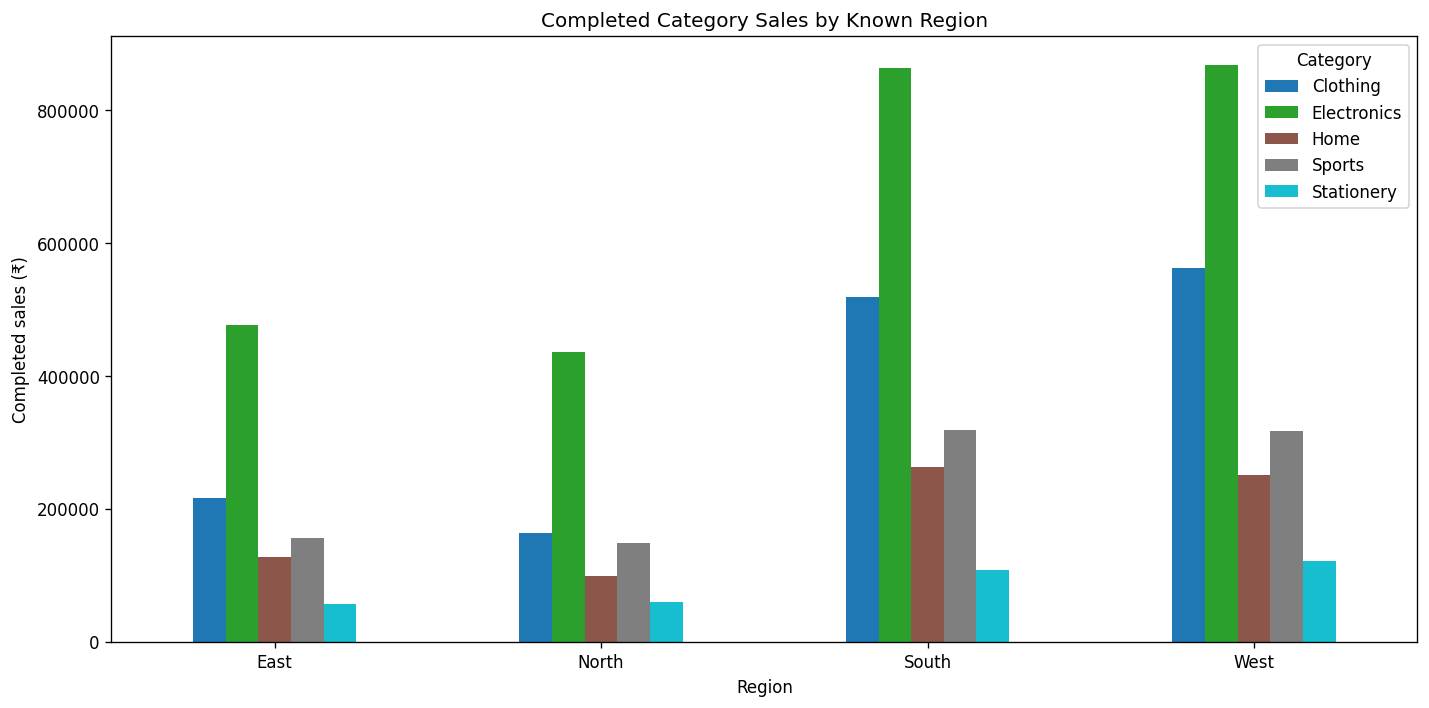

In [12]:
known_regions = completed_sales[completed_sales['region'] != 'Unknown']
region_category_sales = known_regions.pivot_table(
    index='region', columns='category', values='sales_value',
    aggfunc='sum', fill_value=0
)
print(region_category_sales.to_string())

regional_winners = pd.DataFrame({
    'winning_category': region_category_sales.idxmax(axis=1),
    'sales_value': region_category_sales.max(axis=1)
})
print('\nBest category by region:')
print(regional_winners.to_string())

region_category_sales.plot(kind='bar', figsize=(12, 6), colormap='tab10')
plt.title('Completed Category Sales by Known Region')
plt.xlabel('Region')
plt.ylabel('Completed sales (₹)')
plt.xticks(rotation=0)
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**Findings:**

- **East:** Electronics leads with ₹476,426.
- **North:** Electronics leads with ₹435,528.
- **South:** Electronics leads with ₹863,464.
- **West:** Electronics leads with ₹867,884.

## Final checks
These checks ensure the different views reconcile to the same sales total and cleaning did not remove legitimate order lines.

In [13]:
assert len(retail_clean) == len(df) - df.duplicated().sum()
assert retail_clean.duplicated().sum() == 0
assert completed_sales['status'].eq('Completed').all()
assert monthly_sales.sum() == total_sales
assert product_sales.sum() == total_sales
assert all_region_sales.sum() == total_sales
assert region_category_sales.to_numpy().sum() == known_regions['sales_value'].sum()
assert abs(order_totals.mean() - average_order_value) < 0.01
print('All reconciliation checks passed.')

All reconciliation checks passed.


## Executive summary

After removing 20 duplicate records, the dataset contains 3,211 product lines across 1,570 orders. Completed purchases generated **₹6,188,688** across **1,521 orders with completed lines**, with an average completed value of **₹4,068.83 per qualifying order**.

- **Product:** Headphones generated the highest completed sales (₹1,014,594).
- **Volume:** Electronics led unit sales (1,611 units).
- **Geography:** West led known regions (₹2,119,313).
- **Timing:** 2025-11 was the highest-sales month (₹356,351).

### Suggested next investigations
1. Compare stock availability and unit economics for leading products before changing purchase quantities. Sales alone do not establish profitability.
2. Investigate whether high-sales months coincide with promotions or changes in order volume. This file has no promotion data to confirm a cause.
3. Improve region capture so more completed sales can be attributed geographically.

### Limitations
- This is generated practice data, not evidence about a real retail market. Its patterns reflect generation choices.
- There are no costs, customer IDs, discounts, taxes, delivery charges or marketing measures. We cannot calculate profit, retention or marketing ROI.
- Status is recorded at product-line level. An order can include completed and non-completed lines. AOV is defined accordingly.
- Returned and cancelled lines have positive quantities but are excluded from retained sales; no separate refund dates exist.
- Missing labels are preserved as Unknown, not imputed facts.

### Skills demonstrated
Data inspection; missing-value handling; exact deduplication; string cleaning; date conversion; filtering; calculated columns; grouping and aggregation; unique counts; pivot tables; bar and line charts; reconciliations; evidence-based interpretation.
